# Fallback colour: g - i from g - z

The DCR and lateral-colour corrections need g - i. 14% of PSF objects (20% of Gaia stars) have none, mostly because
their brick has no i-band coverage. This notebook tests which other colour predicts g - i accurately and fits the
fallback used by `py_files/colours.py` (written to `py_files/colour_fallback.json`).

Training set: stars with S/N > 50 in g, r, i and z, from the combined catalogues of four slices; half fitted, half
held out. g - z is adopted (Nada, 2026-10-23: use a fallback where accurate), for 0 < g - i < 3.2 only (shaded: excluded).

In [1]:
import os, sys, json
import numpy as np
import fitsio
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
ps.apply()
SLICES = ['000', '020', '040', '060']
COLS = ['flux_g', 'flux_r', 'flux_i', 'flux_z', 'flux_ivar_g', 'flux_ivar_r', 'flux_ivar_i', 'flux_ivar_z', 'nobs_i',
        'ref_epoch', 'gaia_phot_bp_mean_mag', 'gaia_phot_rp_mean_mag']
T = np.concatenate([fitsio.read(f'/pscratch/sd/n/nelfalou/legacypm-catalogue/combined/pm-{d}.fits', columns=COLS) for d in SLICES])
with np.errstate(all='ignore'):
    mag = {b: np.where(T['flux_' + b] > 0, 22.5 - 2.5 * np.log10(T['flux_' + b]), np.nan) for b in 'griz'}
    sn = {b: T['flux_' + b] * np.sqrt(T['flux_ivar_' + b]) for b in 'griz'}
rs = lambda v: 1.4826 * np.nanmedian(np.abs(v - np.nanmedian(v)))
gi = mag['g'] - mag['i']
no_gi = ~np.isfinite(gi)
print(f"{len(T):,} PSF objects; no g - i: {no_gi.mean():.1%} (no i coverage for {(T['nobs_i'] == 0)[no_gi].mean():.0%} of these); "
      f"of these, g - z available for {np.isfinite(mag['g'] - mag['z'])[no_gi].mean():.0%}")

16,762,260 PSF objects; no g - i: 14.3% (no i coverage for 80% of these); of these, g - z available for 81%


/global/homes/n/nelfalou/anaconda3/envs/desi-pm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3505: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


$g-z$      held-out robust scatter 0.026 mag, |res| > 0.3: 1.7%; bias by g - i: +0.004, +0.022, +0.023, +0.005, -0.010


/global/homes/n/nelfalou/anaconda3/envs/desi-pm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3505: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


$g-r$      held-out robust scatter 0.139 mag, |res| > 0.3: 12.6%; bias by g - i: +0.041, +0.037, -0.085, -0.180, +0.274


$r-z$      held-out robust scatter 0.121 mag, |res| > 0.3: 5.4%; bias by g - i: -0.101, -0.034, +0.097, +0.127, -0.061


/global/homes/n/nelfalou/anaconda3/envs/desi-pm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3505: RankWarning: Polyfit may be poorly conditioned
  exec(code_obj, self.user_global_ns, self.user_ns)


$G_{\rm BP} - G_{\rm RP}$ held-out robust scatter 0.174 mag, |res| > 0.3: 25.0%; bias by g - i: -0.231, -0.195, -0.117, +0.015, +0.096


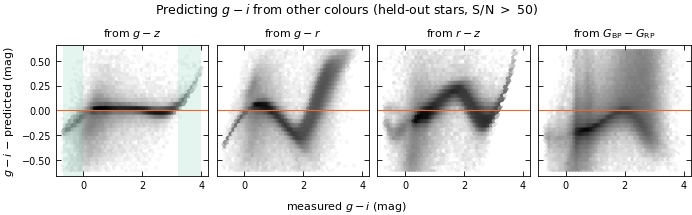

In [2]:
# Candidate predictors: held-out scatter and bias of a cubic fit, overall and by g - i
bprp = T['gaia_phot_bp_mean_mag'] - T['gaia_phot_rp_mean_mag']
PRED = {'$g-z$': mag['g'] - mag['z'], '$g-r$': mag['g'] - mag['r'], '$r-z$': mag['r'] - mag['z'],
        r'$G_{\rm BP} - G_{\rm RP}$': np.where((T['ref_epoch'] > 0) & (bprp > -0.5), bprp, np.nan)}
hi = np.all([sn[b] > 50 for b in 'griz'], axis=0) & np.isfinite(gi) & (gi > -0.7) & (gi < 4)
rng = np.random.default_rng(0)
train = rng.random(len(T)) < 0.5
gbins = np.array([-0.5, 0.5, 1, 1.5, 2.5, 4])
FITS = {}
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.2), sharey=True, constrained_layout=True)
for ax, (name, x) in zip(axes, PRED.items()):
    m = hi & np.isfinite(x)
    p = np.polyfit(x[m & train], gi[m & train], 3)
    te = m & ~train
    res = gi[te] - np.polyval(p, x[te])
    FITS[name] = (p, x[m & train])
    print(f'{name:10s} held-out robust scatter {rs(res):.3f} mag, |res| > 0.3: {np.mean(np.abs(res) > 0.3):.1%}; '
          'bias by g - i: ' + ', '.join(f'{np.nanmedian(res[(gi[te] >= a) & (gi[te] < b)]):+.3f}' for a, b in zip(gbins, gbins[1:])))
    ax.hexbin(gi[te], res, gridsize=50, extent=(-0.7, 4, -0.6, 0.6), bins='log', cmap=ps.DENSITY, mincnt=1)
    ax.axhline(0, color=ps.SERIES[1], lw=0.8)
    ax.set_title(f'from {name}')
    if name == '$g-z$':
        ax.axvspan(-0.7, 0, color=ps.SERIES[2], alpha=0.12, lw=0); ax.axvspan(3.2, 4, color=ps.SERIES[2], alpha=0.12, lw=0)
axes[0].set_ylabel(r'$g-i$ $-$ predicted (mag)')
fig.supxlabel(r'measured $g-i$ (mag)', fontsize=8)
fig.suptitle(r'Predicting $g-i$ from other colours (held-out stars, S/N $>$ 50)')
plt.savefig('plots/colour_fallback.pdf')

In [3]:
# Adopted: g - z, only where the prediction is unbiased: measured 0 < g - i < 3.2 (the residuals drift to -0.2 mag
# bluewards and up to +0.4 mag redwards). Valid g - z range = where the cubic gives g - i in that interval.
p, xtr = FITS['$g-z$']
GI_LO, GI_HI = 0.0, 3.2
xs = np.linspace(np.percentile(xtr, 0.1), np.percentile(xtr, 99.9), 5001); ys = np.polyval(p, xs)
assert np.all(np.diff(ys) > 0), 'cubic not monotonic over the training range'
gz_lo, gz_hi = np.interp([GI_LO, GI_HI], ys, xs)
m = hi & ~train & np.isfinite(PRED['$g-z$']) & (PRED['$g-z$'] >= gz_lo) & (PRED['$g-z$'] <= gz_hi)
res = gi[m] - np.polyval(p, PRED['$g-z$'][m])
print(f'valid g - z {gz_lo:.3f} .. {gz_hi:.3f}: held-out robust scatter {rs(res):.3f} mag, median {np.median(res):+.3f}, '
      f'|res| > 0.3: {np.mean(np.abs(res) > 0.3):.1%}')
model = {'description': 'g - i = polyval(coeffs, g - z) for objects without a measured g - i (py_files/colours.py)',
         'coeffs': [float(c) for c in p], 'gz_min': float(gz_lo), 'gz_max': float(gz_hi),
         'fit': {'notebook': 'run/colour-fallback.ipynb', 'date': '2026-10-23', 'slices': SLICES,
                 'selection': 'PSF objects with S/N > 50 in griz, -0.7 < g - i < 4', 'n_train': int(len(xtr))}}
json.dump(model, open('../py_files/colour_fallback.json', 'w'), indent=1)
print(json.dumps({k: model[k] for k in ('coeffs', 'gz_min', 'gz_max')}))

valid g - z -0.124 .. 3.970: held-out robust scatter 0.025 mag, median +0.011, |res| > 0.3: 1.5%
{"coeffs": [-0.020530964595759815, 0.10056295273851584, 0.7085986235210736, 0.08640139041836382], "gz_min": -0.12417663432003101, "gz_max": 3.970256943639225}
